# 실습 3. 시계열 AI(TimesFM 3)로 인플루엔자 입원 예측하기

**이 실습에서 할 일**
- 미국 CDC가 공개한 **주별 인플루엔자 입원 건수**로 다음 4주를 예측합니다.
- 시계열 파운데이션 모델 **TimesFM 3**과 가장 단순한 기준인 "지난주 값이 그대로 간다"를 비교합니다.

**TimesFM 3는 어떻게 예측하나요?**
수많은 시계열로 미리 학습된 모델이라, 우리 자료로 학습하지 않고 **과거 값만 넣으면** 미래 값과 예측 범위를 바로 냅니다.

> 실제 감시 업무처럼 "그때 알 수 있었던 자료만" 쓰는 평가는 아닙니다. 2026-10-14에 고정한, 이후 수정된 자료로 하는 과거 평가입니다.

**진행 방법**
- 위에서부터 셀 왼쪽의 ▶ 버튼(또는 `Ctrl+Enter`)을 눌러 **순서대로** 실행하세요. 코드는 몰라도 됩니다.
- ⚙️ 표시가 있는 셀에서만 설정을 바꿉니다. 설정을 바꾸면 그 셀부터 아래로 다시 실행하세요.
- 처음 실행할 때 "이 노트는 Google에서 작성하지 않았습니다"라는 경고가 나오면 **[무시하고 계속하기]**를 누르세요.
- 설치 후 "런타임을 다시 시작하라"는 안내가 나오더라도 이 실습에서는 다시 시작하지 않아도 됩니다.

In [1]:
#@title ① 준비: 필요한 도구 설치 (처음 한 번, 1~2분)
%pip install -q timesfm==3.0.2 koreanize-matplotlib==0.1.1

import warnings; warnings.filterwarnings("ignore")
import logging; logging.disable(logging.WARNING)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import koreanize_matplotlib  # 그래프에 한글 글꼴을 적용합니다
from IPython.display import display, Markdown, HTML
pd.set_option("display.precision", 2)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("✅ 준비 완료 | 계산 장치:", "GPU" if DEVICE.type == "cuda" else "CPU")
if DEVICE.type != "cuda":
    print("   CPU로도 실행됩니다. 더 빠르게 하려면 메뉴 [런타임] → [런타임 유형 변경] → [T4 GPU]를 고르세요.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.1/125.1 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 58.3 MB/s eta 0:00:00
✅ 준비 완료 | 계산 장치: GPU


In [2]:
#@title 🔧 도구 함수 불러오기 (실행만 하세요)

FLU_URL = ("https://raw.githubusercontent.com/cdcepi/FluSight-forecast-hub/"
           "e4e60ab1a05fddc496eefcde60b6351b73a06daa/target-data/target-hospital-admissions.csv")
LOCATIONS = {"미국 전체": "US", "캘리포니아": "06", "뉴욕": "36", "텍사스": "48"}
_MODEL = None


def load_flu(location_name):
    """CDC FluSight의 주별 인플루엔자 입원 건수(2022-02-05 ~ 2026-10-10, 2026-10-14 고정본)."""
    df = pd.read_csv(FLU_URL, dtype={"location": str}, parse_dates=["date"])
    s = df[df["location"] == LOCATIONS[location_name]][["date", "value"]]
    return s.sort_values("date").reset_index(drop=True)


def load_my_series(path, date_col, value_col):
    df = pd.read_csv(path)
    missing = [c for c in (date_col, value_col) if c not in df.columns]
    if missing:
        raise ValueError(f"CSV에 없는 열 이름입니다: {missing}. CSV에 있는 열: {list(df.columns)}")
    s = pd.DataFrame({"date": pd.to_datetime(df[date_col]), "value": pd.to_numeric(df[value_col], errors="coerce")})
    return s.sort_values("date").reset_index(drop=True)


def check_series(s, context, horizon, n_origins):
    if s["date"].duplicated().any():
        raise ValueError("같은 날짜가 두 번 이상 있습니다.")
    if s["value"].isna().any():
        raise ValueError("값이 비어 있는 시점이 있습니다. 빈칸을 채우거나 지운 뒤 다시 실행하세요.")
    gaps = s["date"].diff().dropna()
    if gaps.nunique() != 1:
        raise ValueError("시점 간격이 일정해야 합니다(예: 매주 같은 요일). 빠진 시점이 있는지 확인하세요.")
    need = context + horizon + n_origins - 1
    if len(s) < need:
        raise ValueError(f"자료가 {len(s)}개 시점뿐입니다. 이 설정에는 최소 {need}개가 필요합니다.")


def timesfm_forecast(contexts, horizon, make_positive=True):
    """TimesFM 3: 과거 값만 넣으면 추가 학습 없이 미래 값과 예측 범위(10~90% 분위수)를 냅니다."""
    global _MODEL
    from timesfm3 import TimesFM3Forecaster
    if _MODEL is None:
        print("TimesFM 3 모델을 내려받는 중입니다(처음 한 번만, 약 1분)...")
        _MODEL = TimesFM3Forecaster.from_pretrained("google/timesfm-3.0-pytorch", device=DEVICE.type,
                                                    per_core_batch_size=4)
    outs = list(_MODEL.predict_batch(contexts, horizon=horizon, return_quantiles=True, make_positive=make_positive))
    return (np.stack([o.forecast for o in outs]), np.stack([o.quantiles[:, 0] for o in outs]),
            np.stack([o.quantiles[:, 8] for o in outs]))


def run_backtest(s, context, horizon, n_origins, make_positive):
    """마지막 n_origins개 시작점에서, 그 시점까지의 자료만 보고 다음 horizon개 시점을 예측합니다."""
    y = s["value"].to_numpy(float)
    cuts = list(range(len(y) - horizon - n_origins + 1, len(y) - horizon + 1))
    pred, q10, q90 = timesfm_forecast([y[c - context:c] for c in cuts], horizon, make_positive)
    rows = []
    for i, c in enumerate(cuts):
        for h in range(horizon):
            rows.append({"예측 시작일": s["date"][c - 1].date(), "대상 날짜": s["date"][c + h].date(), "몇 시점 뒤": h + 1,
                         "실제": y[c + h], "TimesFM 3": pred[i, h], "하한(10%)": q10[i, h], "상한(90%)": q90[i, h],
                         "지난 값 그대로": y[c - 1]})
    return pd.DataFrame(rows), cuts


def summarize(result):
    rows = []
    for h in sorted(result["몇 시점 뒤"].unique()) + ["전체"]:
        part = result if h == "전체" else result[result["몇 시점 뒤"] == h]
        rows.append({"몇 시점 뒤": h,
                     "TimesFM 3 오차(MAE)": (part["실제"] - part["TimesFM 3"]).abs().mean(),
                     "지난 값 그대로 오차(MAE)": (part["실제"] - part["지난 값 그대로"]).abs().mean()})
    return pd.DataFrame(rows).round(1)


def plot_last_forecast(s, result, cuts, title, unit):
    last = result[result["예측 시작일"] == result["예측 시작일"].max()]
    c = cuts[-1]
    fig, ax = plt.subplots(figsize=(11, 4.6))
    ax.plot(s["date"][max(0, c - 26):c], s["value"][max(0, c - 26):c], color="#1f77b4", label="과거 관측값")
    dates = pd.to_datetime(last["대상 날짜"])
    ax.fill_between(dates, last["하한(10%)"], last["상한(90%)"], alpha=0.2, color="#2ca02c", label="TimesFM 예측 범위(10~90%)")
    ax.plot(dates, last["실제"], "o-", color="black", label="실제 값(정답)")
    ax.plot(dates, last["TimesFM 3"], "o-", color="#2ca02c", label="TimesFM 3 예측")
    ax.plot(dates, last["지난 값 그대로"], "--", color="#d62728", label="지난 값 그대로(기준)")
    ax.axvline(s["date"][c - 1], color="grey", ls=":", label="예측 시작 시점")
    ax.set(title=title, xlabel="날짜", ylabel=unit)
    ax.legend(fontsize=9, loc="upper left")
    ax.grid(alpha=0.2)
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

print("✅ 도구 함수 준비 완료")

✅ 도구 함수 준비 완료


## ② 데이터 보기

기본 예제는 CDC FluSight의 **미국 전체 주별 인플루엔자 입원 건수** 245주(2022-02 ~ 2026-10)입니다. 캘리포니아·뉴욕·텍사스도 고를 수 있습니다.

> **내 데이터로 해 보기**: `날짜` 열과 `값` 열이 있는 CSV면 됩니다(예: 주별 응급실 방문 건수, 일별 신고 건수). 간격이 일정하고 빠진 시점이 없어야 합니다.

캘리포니아 주별 인플루엔자 입원 건수: 245개 시점 (2022-02-05 ~ 2026-10-10)


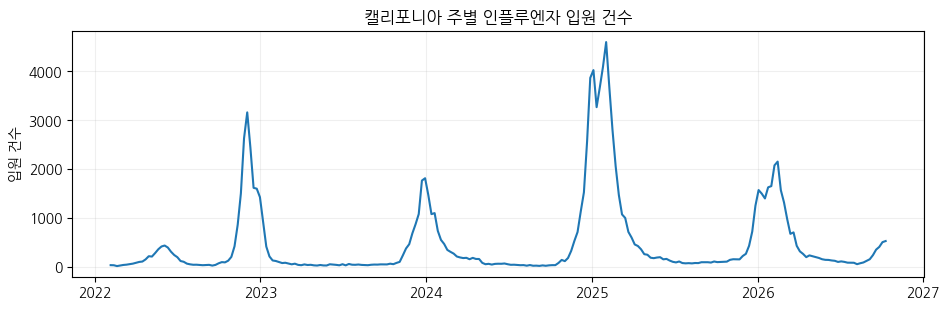

In [3]:
#@title ⚙️ ② 데이터 고르기
LOCATION = "캘리포니아"  #@param ["미국 전체", "캘리포니아", "뉴욕", "텍사스"]
#@markdown ---
#@markdown **내 데이터를 쓸 때만** 채우세요. 먼저 왼쪽 📁(파일) 창에 CSV를 올립니다.
USE_MY_DATA = False  #@param {type:"boolean"}
MY_CSV_FILE = "my_series.csv"  #@param {type:"string"}
DATE_COLUMN = "date"  #@param {type:"string"}
VALUE_COLUMN = "value"  #@param {type:"string"}
#@markdown 값이 0 이상이어야 하는 자료(건수 등)면 체크하세요.
NON_NEGATIVE = True  #@param {type:"boolean"}

series = load_my_series(MY_CSV_FILE, DATE_COLUMN, VALUE_COLUMN) if USE_MY_DATA else load_flu(LOCATION)
SERIES_TITLE = "내 데이터" if USE_MY_DATA else f"{LOCATION} 주별 인플루엔자 입원 건수"
UNIT = VALUE_COLUMN if USE_MY_DATA else "입원 건수"
print(f"{SERIES_TITLE}: {len(series)}개 시점 ({series['date'].min().date()} ~ {series['date'].max().date()})")
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(series["date"], series["value"])
ax.set(title=SERIES_TITLE, ylabel=UNIT)
ax.grid(alpha=0.2)
plt.show()

In [4]:
#@title ⚙️ ③ 예측 설정
#@markdown 모델에게 보여 줄 과거 기간(시점 수)
CONTEXT_WEEKS = 104  #@param [52, 104, 156] {type:"raw"}
#@markdown 평가할 예측 시작점 개수: 1 = 마지막 4주만, 12 = 최근 12개 시작점에서 반복
N_ORIGINS = 12  #@param [1, 12] {type:"raw"}
HORIZON = 4  # 앞으로 4시점(4주)을 예측합니다.

In [5]:
# ③ 예측 실행
check_series(series, CONTEXT_WEEKS, HORIZON, N_ORIGINS)
result, cuts = run_backtest(series, CONTEXT_WEEKS, HORIZON, N_ORIGINS, make_positive=NON_NEGATIVE)
print(f"✅ 예측 완료 | 과거 {CONTEXT_WEEKS}시점을 보고 {HORIZON}시점 앞을 예측, 시작점 {N_ORIGINS}개")

TimesFM 3 모델을 내려받는 중입니다(처음 한 번만, 약 1분)...


config.json:   0%|          | 0.00/1.27k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.32GB            

model.safetensors: downloading bytes:           |  0.00B            

✅ 예측 완료 | 과거 104시점을 보고 4시점 앞을 예측, 시작점 12개


## ④ 결과 보기

- **오차(MAE)**: 실제 값과 예측 값 차이의 평균입니다. 작을수록 정확합니다.
- **지난 값 그대로**: "다음 4주도 지난주와 같다"고 보는 가장 단순한 예측입니다. 좋은 모델이라면 이것보다 나아야 합니다.
- 초록 음영은 TimesFM이 "실제 값이 이 범위 안에 있을 것"이라고 제시한 10~90% 범위입니다. 통계적으로 보정된 신뢰구간은 아닙니다.

,몇 시점 뒤,TimesFM 3 오차(MAE),지난 값 그대로 오차(MAE)
0,1,26.8,30.5
1,2,54.9,59.9
2,3,82.9,96.4
3,4,116.8,133.7
4,전체,70.4,80.1


**해석**: TimesFM 3의 평균 오차는 **70**, 지난 값 그대로는 **80**입니다. → TimesFM 3가 오차를 **12%** 줄였습니다. 실제 값 48개 중 44%가 TimesFM 예측 범위 안에 들어왔습니다.

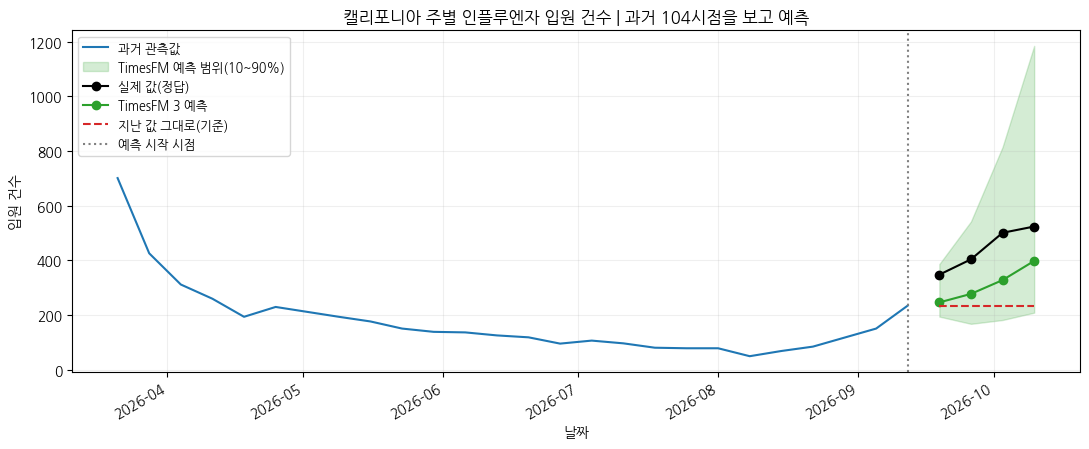

In [6]:
# ④ 결과 표와 그림
summary = summarize(result)
display(summary)
overall = summary.set_index("몇 시점 뒤").loc["전체"]
model_mae, base_mae = overall["TimesFM 3 오차(MAE)"], overall["지난 값 그대로 오차(MAE)"]
inside = ((result["실제"] >= result["하한(10%)"]) & (result["실제"] <= result["상한(90%)"])).mean()
display(Markdown(
    f"**해석**: TimesFM 3의 평균 오차는 **{model_mae:,.0f}**, 지난 값 그대로는 **{base_mae:,.0f}**입니다. "
    + (f"→ TimesFM 3가 오차를 **{(1 - model_mae / base_mae) * 100:.0f}%** 줄였습니다. " if model_mae < base_mae
       else "→ 이번 설정에서는 단순 기준이 더 정확했습니다. ")
    + f"실제 값 {len(result)}개 중 {inside:.0%}가 TimesFM 예측 범위 안에 들어왔습니다."))
if N_ORIGINS == 1:
    display(Markdown("※ 4개 시점만 평가했습니다. 일반적인 성능을 보려면 `N_ORIGINS = 12`로 바꿔 보세요."))
plot_last_forecast(series, result, cuts, f"{SERIES_TITLE} | 과거 {CONTEXT_WEEKS}시점을 보고 예측", UNIT)

## ⑤ 바꿔 보기

1. `CONTEXT_WEEKS`를 **52**로 바꿔 보세요. 과거 자료를 **덜** 보여 주면 나빠질까요?
2. `N_ORIGINS`를 **12**로 바꿔 최근 12개 시작점에서 반복 평가해 보세요.
3. `LOCATION`을 다른 주로 바꿔 보세요.

> **생각해 볼 점**
> - TimesFM 3는 학습 없이도 "지난 값 그대로"보다 4주 예측 오차를 크게 줄였습니다.
> - 과거 자료가 많다고 항상 좋은 것은 아닙니다. 오래전 유행 양상이 지금과 다르면 오히려 방해가 될 수 있습니다.
> - 기본 설정(시작점 1개)은 4개 값만 평가하므로 우연의 영향이 큽니다. 여러 시작점의 결과를 함께 보세요.